# Questão 8 — O formato da loss sob desbalanceamento de classes

## A pergunta

> *Qual loss da mais resultado na classe minoritária a FLOPs iguais, e ela muda a geometria da
> representação oculta como Müller et al. afirmam?*

76 % das linhas do Adult são `<=50K`. A entropia cruzada trata todas as linhas igualmente, e o
modelo pode marcar 0,76 ignorando a classe minoritária. Uma família de losses tenta corrigir
isso sem custo de FLOPs: a **focal** reduz o peso dos exemplos fáceis, o **label smoothing**
suaviza os alvos e a **PolyLoss** repondera o primeiro termo da expansão da entropia cruzada.
Este notebook mede se alguma delas funciona sem aumentar o custo, usando somente a egine proposta do repositório (`bert_cpu`).

## O que a literatura prevê para este cenário, e as hipóteses

Os quatro artigos trabalham a três ordens de grandeza daqui (ImageNet, COCO, redes profundas
em GPU). O que cada um prevê quando trazido para um MLP raso em 108 features tabulares, com
24 % de positivos:

| Artigo | O que afirma | O que prevê aqui |
|---|---|---|
| Lin et al. (focal) | reduzir o peso dos exemplos fáceis resolve o desbalanceamento extremo (~1:1000) da detecção densa | com 1:3 e poucos exemplos "triviais", o ganho deve ser pequeno; sem o termo $\alpha$, a focal não desloca a fronteira para a minoria |
| Szegedy et al. (label smoothing) | suavizar os alvos regulariza e evita logits enormes | pouco a regularizar em 100 passos de um modelo com 7 mil parâmetros |
| Müller et al. | o smoothing aperta os clusters da penúltima camada em volta dos templates e melhora a calibração | clusters mais apertados e silhueta maior; calibração melhor *só se* a CE estiver superconfiante |
| Leng et al. (Poly-1) | ajustar o peso do termo $(1-p_t)$ rende alguns décimos de ponto em vários benchmarks | um efeito, se houver, da ordem de décimos de ponto, perto do ruído entre seeds |

Hipóteses, na forma em que podem ser refutadas:

- **H1.** Nenhuma das três losses "de formato" melhora a acurácia balanceada no teste em mais
  de um desvio-padrão entre seeds em relação à CE.
- **H2.** O que a CE ponderada ganha no recall de `>50K` é um deslocamento do limiar: a CE com
  o limiar ajustado na validação alcança a mesma acurácia balanceada (±1 dp) sem FLOPs extras.
- **H3.** O label smoothing aumenta a silhueta da penúltima camada (o `silhouette_score` do
  `benchmark.py`) e aperta os clusters no plano dos templates, mais quanto maior o
  $\varepsilon$, como afirmam Müller et al.
- **H4.** Esse aperto não se traduz em melhor ordenação: o ROC-AUC do label smoothing não
  supera o da CE.

In [1]:
import gc
import json
import pathlib
import sys
import time

ROOT = pathlib.Path.cwd()
while not (ROOT / "bert_cpu").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import datasets
from bert_cpu import engine as cpu
from research.benchmark import (MLP, Result, baseline_mlp, load_adult_cached, pareto,
                                run_adult, silhouette_score, summarize, train_val_split)

HERE = ROOT / "experiments" / "loss_imbalance"
RESULTS = HERE / "results"
FIGURES = HERE / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Paleta e estilo das figuras
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.style.use("default")
plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

START_TIME = time.time()
print("pronto — engine importado de", ROOT)

pronto — engine importado de C:\Users\pedro\PycharmProjects\BERT-cpu


## 1. O problema e o que fica fixo

Cada seed sorteia uma divisão 80/20 de `adult.data` em treino e validação e fixa a
inicialização dos pesos. O `adult.test` (16 281 linhas) só é olhado nos runs finais.

O que torna a comparação **a FLOPs iguais** é fixar todo o resto: o mesmo MLP da q05, o mesmo
Adam full-batch com lr 1e-2 e os mesmos 100 passos. A loss só acrescenta algumas operações
elemento a elemento no topo do grafo, e o contador do engine vai mostrar quanto isso custa.

Antes de treinar, vale fixar a referência burra: sempre responder `<=50K` acerta 76 %, e não
encontra nenhum `>50K`. Por isso a acurácia sozinha esconde o efeito que queremos medir.

In [2]:
train_ds, test_ds = load_adult_cached()
print(train_ds, test_ds)
for split_name, dataset in (("treino", train_ds), ("teste", test_ds)):
    print(f"{split_name:7s}: {dataset.y.size:6,d} linhas   fração >50K = {dataset.y.mean():.3f}")
print(f"\n'sempre <=50K' no teste: acurácia {1 - test_ds.y.mean():.3f}")

AdultDataset(split='train', n_features=108, n_samples=32561) AdultDataset(split='test', n_features=108, n_samples=16281)
treino : 32,561 linhas   fração >50K = 0.241
teste  : 16,281 linhas   fração >50K = 0.236

'sempre <=50K' no teste: acurácia 0.764


### O baseline, reproduzido antes de mudar qualquer coisa

O protocolo do projeto pede que o ponto de partida seja reproduzido antes de qualquer
variação. `research/benchmark.py` garante que `run_adult(baseline_mlp, seed=0)` dá a acurácia
de teste da q05, **0,8543**, com **84 227 782 200** FLOPs de treino. A célula seguinte confere isso.

In [26]:
start = time.time()
baseline = run_adult(baseline_mlp, seed=0, name="baseline (q05)")
print(f"acurácia de teste = {baseline.score:.4f}   (q05: 0.8543)")
print(f"FLOPs de treino   = {baseline.train_flops:,}   (q05: 84,227,782,200)")
print(f"tempo             = {time.time() - start:.1f} s")
del baseline
gc.collect()

acurácia de teste = 0.8543   (q05: 0.8543)
FLOPs de treino   = 84,227,782,200   (q05: 84,227,782,200)
tempo             = 4.4 s


41731

## 2. As cinco losses

**Notação.** O modelo produz os logits $z$ e as probabilidades $p = \mathrm{softmax}(z)$. Para cada exemplo, $p_t$ é a probabilidade dada à **classe correta** ($t$ de *target*). No Adult, $K = 2$ classes: `<=50K` (majoritária, 75,9%) e `>50K` (minoritária, 24,1%).

| Loss | Fórmula por exemplo | Hiperparâmetro | O que muda em relação à CE |
|---|---|---|---|
| CE | $-\log p_t$ | — | (referência) |
| CE ponderada | $w_t\,(-\log p_t)$ | — | pesa cada exemplo pela **classe** |
| Focal (Lin et al.) | $-(1-p_t)^{\gamma}\log p_t$ | $\gamma$ | pesa cada exemplo pela **dificuldade** |
| Label smoothing (Szegedy et al.) | $-\sum_c q_c \log p_c$ | $\varepsilon$ | troca o **alvo** por um alvo suavizado |
| Poly-1 (Leng et al.) | $-\log p_t + \varepsilon_1 (1-p_t)$ | $\varepsilon_1$ | soma um termo **linear** à CE |

### 2.1 Cross entropy (CE)

$$\mathcal{L}_{\text{CE}} = -\log p_t$$

É a referência. A loss é zero só quando $p_t = 1$ e cresce rápido quando o modelo erra. Todas as classes contam igual, então, com 76% dos exemplos na classe majoritária, o gradiente é dominado por ela.

Exemplo: $p_t = 0{,}8 \Rightarrow 0{,}223$; $\;p_t = 0{,}2 \Rightarrow 1{,}609$.

### 2.2 CE ponderada por classe

$$\mathcal{L}_{\text{W}} = \frac{\sum_i w_{t_i}\,(-\log p_{t_i})}{\sum_i w_{t_i}}, \qquad w_c = \frac{N}{K\,N_c} = \frac{1}{K\,f_c}, \quad f_c = \frac{N_c}{N}$$

em que $N$ é o total de exemplos de treino, $N_c$ é o número de exemplos da classe $c$ e $f_c$ é a fração dessa classe.

- $1/f_c$ é o **inverso da frequência**: quanto mais rara a classe, maior o peso.
- $1/K$ só ajusta a escala: cada classe soma o mesmo peso total ($N_c\,w_c = N/K$) e o peso médio por exemplo fica em 1.
- Dividir por $\sum w$ faz uma média ponderada no lote, mantendo a loss na escala da CE (o learning rate não muda).
- Com classes balanceadas, todo $w_c = 1$ e a fórmula vira a CE.

| Classe | $N_c$ | $f_c$ | $w_c$ |
|---|---|---|---|
| `>50K` (minoritária) | 7 841 | 0,241 | **2,08** |
| `<=50K` (majoritária) | 24 720 | 0,759 | **0,66** |

Um erro na classe minoritária pesa cerca de **3,2×** mais. Na prática, isso equivale a deslocar o limiar de decisão a favor da classe rara.

### 2.3 Focal loss

$$\mathcal{L}_{\text{FL}} = -(1-p_t)^{\gamma}\,\log p_t$$

O fator $(1-p_t)^{\gamma}$ diminui o peso dos exemplos **fáceis** (com $p_t$ perto de 1) e mantém o dos difíceis. Com $\gamma = 0$ ela é a CE; quanto maior o $\gamma$, mais forte o efeito. A ideia do artigo é que, com desbalanceamento, a maioria dos exemplos fáceis vem da classe majoritária, e a focal impede que eles dominem o treino.

Exemplo com $\gamma = 2$: $p_t = 0{,}8 \Rightarrow 0{,}2^2 \cdot 0{,}223 = 0{,}009$; $\;p_t = 0{,}2 \Rightarrow 0{,}8^2 \cdot 1{,}609 = 1{,}030$. Na CE o erro feio pesa 7× o fácil; na focal, 116×.

Usamos a versão sem o peso $\alpha$ por classe do artigo. Com $\alpha$, ela passaria a misturar o efeito da CE ponderada, que já está na comparação, e não daria para separar o efeito do formato da loss.

### 2.4 Label smoothing

$$\mathcal{L}_{\text{LS}} = -\sum_{c=1}^{K} q_c \log p_c, \qquad q = (1-\varepsilon)\,\mathbf{1}_t + \frac{\varepsilon}{K}$$

É a CE com o **alvo trocado**: em vez de 1 na classe correta e 0 na outra, o alvo vira $1 - \varepsilon + \varepsilon/K$ e $\varepsilon/K$. Com $\varepsilon = 0{,}1$ e $K = 2$: $q = (0{,}95;\ 0{,}05)$. A loss passa a ser mínima em $p_t = 0{,}95$ e **pune** o modelo se ele ficar mais confiante que isso, o que segura o crescimento dos logits. Segundo Müller et al., isso também aperta os clusters de cada classe na camada oculta.

Exemplo com $\varepsilon = 0{,}1$: $p_t = 0{,}8 \Rightarrow -(0{,}95 \log 0{,}8 + 0{,}05 \log 0{,}2) = 0{,}292$. O mínimo possível é 0,199, em $p_t = 0{,}95$, e não 0.

### 2.5 Poly-1

$$\mathcal{L}_{\text{Poly-1}} = -\log p_t + \varepsilon_1\,(1-p_t)$$

A CE pode ser escrita como a série $\sum_{j \ge 1} (1-p_t)^j / j$. O Poly-1 muda só o peso do **primeiro termo**, de 1 para $1 + \varepsilon_1$. Com $\varepsilon_1 > 0$, o modelo continua sendo empurrado com força mesmo nos exemplos que já acerta; com $\varepsilon_1 < 0$, o contrário. Com $\varepsilon_1 = 0$ é a CE.

Exemplo com $\varepsilon_1 = 1$: $p_t = 0{,}8 \Rightarrow 0{,}223 + 0{,}2 = 0{,}423$; $\;p_t = 0{,}2 \Rightarrow 1{,}609 + 0{,}8 = 2{,}409$.

### Implementação

Todas usam o `softmax` do engine e são montadas só com operações do `Tensor`, então o `backward()` chega aos pesos sem código novo. Cada uma tem a assinatura `loss_fn(model, X, y) -> Tensor escalar`, que é o que `research.benchmark.run_adult` espera.

In [4]:
def probabilities(model, X):
    """Probabilidade de cada classe para cada pessoa: tabela (N pessoas, K classes)."""
    return model(X).T.softmax(axis=-1)


def onehot_targets(y, probs):
    """Rótulos viram linhas 0/1, no mesmo formato de probs. Ex.: y = [0, 1] -> [[1, 0], [0, 1]]."""
    targets = np.zeros(probs.shape, dtype=probs.data.dtype)
    targets[np.arange(len(y)), y] = 1.0
    return targets


def true_class_prob(probs, targets):
    """p_t: zera as classes erradas e soma o que sobrou em cada linha."""
    return (probs * targets).sum(axis=-1)


def ce_loss():
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        prob_true = true_class_prob(probs, onehot_targets(y, probs))
        return -prob_true.log().mean()
    return loss_fn


def weighted_ce_loss():
    """Pesos inversos à frequência, calculados nos rótulos do treino (o batch é o treino todo)."""
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        prob_true = true_class_prob(probs, onehot_targets(y, probs))
        n_classes = probs.shape[-1]
        class_counts = np.bincount(y)                          # N_c de cada classe
        weight = len(y) / (n_classes * class_counts[y])        # w_c = N / (K N_c), um por pessoa
        return -(prob_true.log() * weight).sum() / weight.sum()
    return loss_fn


def focal_loss(gamma):
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        prob_true = true_class_prob(probs, onehot_targets(y, probs))
        modulator = (1.0 + 1e-12 - prob_true) ** gamma         # 1e-12: evita 0 ** (gamma-1) no backward
        return -(modulator * prob_true.log()).mean()
    return loss_fn


def label_smoothing_loss(epsilon):
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        n_classes = probs.shape[-1]
        smooth_targets = onehot_targets(y, probs) * (1 - epsilon) + epsilon / n_classes
        return -(probs.log() * smooth_targets).sum(axis=-1).mean()
    return loss_fn


def poly1_loss(epsilon1):
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        prob_true = true_class_prob(probs, onehot_targets(y, probs))
        return (-prob_true.log() + (1.0 - prob_true) * epsilon1).mean()
    return loss_fn

LOSSES = {"ce": ce_loss,
          "wce": weighted_ce_loss,
          "focal": focal_loss,
          "ls": label_smoothing_loss,
          "poly1": poly1_loss}


def build_loss(family, param=None):
    """Ex.: build_loss("ce") -> ce_loss(); build_loss("focal", 0.5) -> focal_loss(0.5)."""
    return LOSSES[family]() if param is None else LOSSES[family](param)

NAMES = {"ce": "CE", "wce": "Weighted CE", "focal": "Focal γ", "ls": "Label smoothing ε", "poly1": "Poly-1 ε₁"}


def label(family, param=None):
    """Ex.: label("ce") -> "CE"; label("focal", 0.5) -> "Focal γ=0.5"."""
    return NAMES[family] if param is None else f"{NAMES[family]}={param:g}"

### Conferindo as losses

Três checagens num modelo minúsculo:

1. Com o hiperparâmetro em zero, focal, label smoothing e Poly-1 **viram a CE**; a diferença
   para o `cross_entropy` da biblioteca tem de ser ~1e-16.
2. O gradiente que o engine produz para os pesos da última camada tem de bater com
   **diferenças finitas centrais** (o mesmo critério dos exercícios q01–q04: ~1e-9 ou menos).
3. Cálculo manual esperado dos valores das losses

In [5]:
from research.benchmark import default_loss


def loss_gradient_check(loss_fn, model, X, y, step=1e-6):
    """Maior diferença entre o gradiente do backward e o de diferenças finitas, nos pesos de fc2."""
    for parameter in model.parameters():
        parameter.zero_grad()
    loss_fn(model, X, y).backward()

    weight = model.fc2.weight
    analytic = weight.grad.copy()
    numeric = np.zeros_like(analytic)
    for index in range(weight.data.size):
        original = weight.data.flat[index]
        weight.data.flat[index] = original + step
        loss_up = float(loss_fn(model, X, y).data)
        weight.data.flat[index] = original - step
        loss_down = float(loss_fn(model, X, y).data)
        weight.data.flat[index] = original                       # devolve o peso original
        numeric.flat[index] = (loss_up - loss_down) / (2 * step)  # derivada central
    return np.abs(analytic - numeric).max()


def check_losses() -> None:
    """(1) Com hiperparâmetro 0, focal, LS e Poly-1 viram a CE do benchmark.
    (2) O backward de cada loss bate com diferenças finitas."""
    cpu.set_seed(0)
    model = MLP(5, hidden=8)
    X = cpu.Tensor(np.random.randn(5, 40), requires_grad=False)
    y = (np.random.rand(40) < 0.3).astype(int)            # ~30% de classe 1, desbalanceado
    all_ok = True

    print("1. Casos que devem ser iguais à CE do benchmark (default_loss):\n")
    reference = float(default_loss(model, X, y).data)
    for family, param in [("ce", None), ("focal", 0.0), ("ls", 0.0), ("poly1", 0.0)]:
        difference = abs(float(build_loss(family, param)(model, X, y).data) - reference)
        ok = difference < 1e-10
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} |diferença| = {difference:.1e}  -> {'PASS' if ok else 'FAIL'}")

    print("\n2. Gradiente (backward analítico vs diferenças finitas):\n")
    for family, param in [("wce", None), ("focal", 0.5), ("focal", 2.0), ("ls", 0.2), ("poly1", 2.0)]:
        worst = loss_gradient_check(build_loss(family, param), model, X, y)
        ok = worst < 1e-6
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} max|analítico - numérico| = {worst:.1e}  -> {'PASS' if ok else 'FAIL'}")

    print("\nTodas as losses passaram." if all_ok else "\nAlguma loss falhou: veja os FAIL acima.")


check_losses()

1. Casos que devem ser iguais à CE do benchmark (default_loss):

  CE                     |diferença| = 1.1e-16  -> PASS
  Focal γ=0              |diferença| = 1.1e-16  -> PASS
  Label smoothing ε=0    |diferença| = 1.1e-16  -> PASS
  Poly-1 ε₁=0            |diferença| = 1.1e-16  -> PASS

2. Gradiente (backward analítico vs diferenças finitas):

  Weighted CE            max|analítico - numérico| = 7.2e-11  -> PASS
  Focal γ=0.5            max|analítico - numérico| = 5.4e-11  -> PASS
  Focal γ=2              max|analítico - numérico| = 2.9e-11  -> PASS
  Label smoothing ε=0.2  max|analítico - numérico| = 4.3e-11  -> PASS
  Poly-1 ε₁=2            max|analítico - numérico| = 2.4e-10  -> PASS

Todas as losses passaram.


In [6]:
class FixedModel:
    """Finge ser um modelo: sempre dá p = (0.2, 0.8) para todas as pessoas."""
    def __init__(self, n):
        self.logits = np.array([[0.0] * n, [np.log(4.0)] * n])   # softmax(0, ln 4) = (0.2, 0.8)
    def __call__(self, X):
        return cpu.Tensor(self.logits, requires_grad=False)


def check_hand_values() -> None:
    """Compara cada loss com o valor calculado à mão."""
    one = FixedModel(1)
    y1 = np.array([1])                       # uma pessoa >50K, então p_t = 0.8
    four = FixedModel(4)
    y4 = np.array([1, 0, 0, 0])              # 1 rara (p_t = 0.8) e 3 comuns (p_t = 0.2)

    cases = [
        ("ce",    None, one,  y1, 0.22314),  # -log(0.8)
        ("focal", 2.0,  one,  y1, 0.00893),  # 0.2² · 0.22314
        ("ls",    0.1,  one,  y1, 0.29246),  # 0.95·0.22314 + 0.05·1.60944
        ("poly1", 1.0,  one,  y1, 0.42314),  # 0.22314 + 1·0.2
        ("ce",    None, four, y4, 1.26287),  # (0.22314 + 3·1.60944) / 4
        ("wce",   None, four, y4, 0.91629),  # pesos 2 e 0.667: (2·0.22314 + 3·0.667·1.60944) / 4
    ]
    all_ok = True
    for family, param, model, y, expected in cases:
        got = float(build_loss(family, param)(model, None, y).data)
        ok = abs(got - expected) < 1e-4
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} esperado {expected:.5f}  obtido {got:.5f}  -> {'PASS' if ok else 'FAIL'}")
    print("\nTodas batem com a conta à mão." if all_ok else "\nAlguma fórmula está errada: veja os FAIL acima.")


check_hand_values()

  CE                     esperado 0.22314  obtido 0.22314  -> PASS
  Focal γ=2              esperado 0.00893  obtido 0.00893  -> PASS
  Label smoothing ε=0.1  esperado 0.29246  obtido 0.29246  -> PASS
  Poly-1 ε₁=1            esperado 0.42314  obtido 0.42314  -> PASS
  CE                     esperado 1.26287  obtido 1.26286  -> PASS
  Weighted CE            esperado 0.91629  obtido 0.91629  -> PASS

Todas batem com a conta à mão.


## 3. O que medir na classe minoritária

A classe 1 (`>50K`) é a minoritária em tudo o que segue. As métricas são as que a questão pede,
mais o ROC-AUC, que a hipótese H4 usa.

- **Precisão e recall de `>50K`.**
- **Acurácia balanceada** $= \tfrac12(\text{recall}_{>50K} + \text{recall}_{\le 50K})$: o
  "sempre `<=50K`" marca 0,5 aqui, não 0,76.
- **ROC-AUC**, que não depende do limiar de decisão. Ele separa duas coisas que uma loss pode
  fazer: *ordenar melhor* os exemplos (o AUC sobe) ou só *deslocar o limiar* (o AUC fica igual
  e a precisão troca por recall).
- **Calibração.** O diagrama de confiabilidade agrupa as previsões em 15 faixas de confiança e
  compara a confiança média com a fração de acertos em cada uma. O ECE (Guo et al. 2017) resume
  o diagrama num número: a distância média entre confiança e acerto. Abaixo da diagonal o
  modelo está superconfiante, acima está subconfiante.

Há também um **controle de custo zero**: o próprio modelo CE, com o limiar em
$p(>50K)$ escolhido na validação para maximizar a acurácia balanceada. Se uma loss só desloca
o limiar, esse controle chega ao mesmo lugar sem gastar nada.

In [7]:
def minority_metrics(prob_positive, labels, threshold=0.5):
    """Acurácia, precisão/recall de >50K e acurácia balanceada num limiar de decisão.

    prob_positive: p(>50K) de cada pessoa. labels: 0 (<=50K) ou 1 (>50K).
    """
    predicted = (prob_positive >= threshold).astype(int)
    true_pos = np.sum((predicted == 1) & (labels == 1))    # >50K encontrados
    false_pos = np.sum((predicted == 1) & (labels == 0))   # <=50K chamados de >50K
    false_neg = np.sum((predicted == 0) & (labels == 1))   # >50K perdidos
    true_neg = np.sum((predicted == 0) & (labels == 0))    # <=50K acertados

    precision = true_pos / max(true_pos + false_pos, 1)
    recall = true_pos / max(true_pos + false_neg, 1)
    majority_recall = true_neg / max(true_neg + false_pos, 1)
    return {
        "accuracy": float((true_pos + true_neg) / len(labels)),
        "minority_precision": float(precision),
        "minority_recall": float(recall),
        "balanced_accuracy": float(0.5 * (recall + majority_recall)),
    }


def roc_auc(prob_positive, labels):
    """Chance de uma pessoa >50K sorteada ter p(>50K) maior que uma <=50K sorteada.

    Não depende de limiar: mede só se o modelo ordena bem as pessoas. Calculada pela
    soma de postos (Mann-Whitney); empates recebem o posto médio.
    """
    order = np.argsort(prob_positive, kind="mergesort")
    sorted_probs = prob_positive[order]
    ranks = np.empty(len(prob_positive))
    start = 0
    while start < len(sorted_probs):
        end = start
        while end + 1 < len(sorted_probs) and sorted_probs[end + 1] == sorted_probs[start]:
            end += 1
        ranks[order[start:end + 1]] = 0.5 * (start + end) + 1.0
        start = end + 1
    n_positive = int((labels == 1).sum())
    n_negative = len(labels) - n_positive
    rank_sum = ranks[labels == 1].sum()
    return float((rank_sum - n_positive * (n_positive + 1) / 2) / (n_positive * n_negative))


def reliability(prob_positive, labels, n_bins=15):
    """Diagrama de confiabilidade e ECE (Guo et al. 2017).

    Agrupa as pessoas pela confiança (a probabilidade da classe prevista) em n_bins faixas
    entre 0,5 e 1 e compara, em cada faixa, a confiança média com a fração de acertos.
    """
    confidence = np.maximum(prob_positive, 1.0 - prob_positive)
    correct = ((prob_positive >= 0.5).astype(int) == labels).astype(float)
    bin_edges = np.linspace(0.5, 1.0, n_bins + 1)
    bin_index = np.clip(np.digitize(confidence, bin_edges[1:-1], right=True), 0, n_bins - 1)

    bin_confidence = np.full(n_bins, np.nan)
    bin_accuracy = np.full(n_bins, np.nan)
    bin_count = np.zeros(n_bins, dtype=int)
    ece = 0.0
    for b in range(n_bins):
        in_bin = bin_index == b
        bin_count[b] = int(in_bin.sum())
        if bin_count[b] > 0:
            bin_confidence[b] = confidence[in_bin].mean()
            bin_accuracy[b] = correct[in_bin].mean()
            ece += bin_count[b] / len(labels) * abs(bin_accuracy[b] - bin_confidence[b])
    return float(ece), bin_confidence, bin_accuracy, bin_count


def evaluate(prob_positive, labels, threshold=0.5):
    """Tudo o que a questão pede sobre classificação: métricas da minoria, ROC-AUC e ECE."""
    metrics = minority_metrics(prob_positive, labels, threshold)
    metrics["roc_auc"] = roc_auc(prob_positive, labels)
    metrics["ece"] = reliability(prob_positive, labels)[0]
    return metrics


def best_threshold(prob_positive, labels):
    """Limiar em p(>50K) que maximiza a acurácia balanceada (escolhido na validação)."""
    candidates = np.linspace(0.02, 0.98, 97)
    scores = [minority_metrics(prob_positive, labels, t)["balanced_accuracy"] for t in candidates]
    return float(candidates[int(np.argmax(scores))])

## 4. A hipótese de Müller et al.

Müller, Kornblith & Hinton projetam as ativações da penúltima camada no plano gerado pelos
**templates** das classes, isto é, as colunas $w_k$ da última camada (o logit da classe $k$ é
$h \cdot w_k$). A afirmação deles: com label smoothing, cada classe vira um **cluster
apertado** em volta do seu template, enquanto com CE as ativações se espalham.

Aqui $h = \mathrm{ReLU}(\text{fc1}(x)) \in \mathbb{R}^{64}$, e os templates são as colunas de
`fc2.weight` sem a linha do bias. Com duas classes o plano tem um eixo especial: a decisão só
depende de $h \cdot (w_1 - w_0)$. Por isso o eixo horizontal das figuras é $w_1 - w_0$ e o
vertical é o resto do plano.

Tudo é medido nas mesmas 2 000 linhas do teste, sorteadas uma vez.

Uma limitação na metade da afirmação de Müller, que os
clusters ficam **equidistantes dos templates das outras classes**, só é testável com $K \ge 3$.
Com $K = 2$ ela é trivial.


### Medidas de geometria

Notação: $h_i \in \mathbb{R}^{64}$ é a ativação da pessoa $i$, $y_i$ a classe dela e $n_c$ o número de pessoas da classe $c$.

**Plano dos templates** (`template_plane`). O eixo horizontal é a direção da decisão, e o vertical é a soma dos templates, ortogonalizada:

$$a = \frac{w_1 - w_0}{\lVert w_1 - w_0 \rVert}, \qquad \tilde b = (w_0 + w_1) - \big((w_0 + w_1)\cdot a\big)\,a, \qquad b = \frac{\tilde b}{\lVert \tilde b \rVert}$$

$$p_i = (h_i \cdot a,\; h_i \cdot b)$$

São duas medidas de aperto:

**Silhueta** (`silhouette_score` do `benchmark.py`, a medida que a questão pede). Para cada pessoa, $\alpha_i$ é a distância média até a própria classe e $\beta_i$ até a outra, com a distância cosseno $1 - \cos(h_i, h_j)$ nas 64 dimensões. Varia de −1 a 1, e maior significa mais separado.

$$s_i = \frac{\beta_i - \alpha_i}{\max(\alpha_i, \beta_i)}, \qquad S = \frac{1}{n}\sum_i s_i$$

**Espalhamento** (o que a Fig. 1 de Müller et al. mostra). O raio médio de cada classe no plano, relativo à distância entre os centros $m_c$ (média dos $p_i$ da classe). Menor significa mais apertado.

$$\mathrm{espalhamento}_c = \frac{\sqrt{\frac{1}{n_c}\sum_{i \in c} \lVert p_i - m_c \rVert^2}}{\lVert m_1 - m_0 \rVert}$$

As duas são relativas, ou invariantes à escala, porque o label smoothing também encolhe as ativações: um espalhamento absoluto menor poderia ser só efeito de tudo ter ficado menor. A diferença entre elas importa na leitura da seção 10: o espalhamento usa distância euclidiana (sente o **tamanho** das ativações), e a silhueta usa cosseno (sente só a **direção**).

In [8]:
def template_plane(hidden, templates):
    # hidden: ativações da camada escondida, (n pessoas, 64)
    # templates: pesos da camada de saída sem a linha do bias, (64, 2)
    #    coluna 0 = template w0 (≤50K), coluna 1 = template w1 (>50K)

    # Eixo horizontal: a direção w1 - w0, com tamanho 1.
    # Andar nessa direção aumenta z1 - z0, ou seja, puxa a decisão para >50K.
    decision_axis = templates[:, 1] - templates[:, 0]
    decision_axis = decision_axis / np.linalg.norm(decision_axis)

    # Eixo vertical: parte de w0 + w1 e tira o pedaço que aponta na direção do eixo da
    # decisão (Gram-Schmidt), para os dois eixos ficarem perpendiculares.
    other_axis = templates[:, 0] + templates[:, 1]
    other_axis = other_axis - (other_axis @ decision_axis) * decision_axis
    # 1e-12 evita dividir por zero se w0 + w1 for paralelo ao eixo (por exemplo, w0 = -w1)
    other_axis = other_axis / max(np.linalg.norm(other_axis), 1e-12)

    # Projeção: o produto escalar com cada eixo dá a coordenada da pessoa nele.
    # Resultado: (n, 2), coluna 0 = x, coluna 1 = y
    return np.stack([hidden @ decision_axis, hidden @ other_axis], axis=1)


def geometry(hidden, labels, templates):
    """As duas medidas de aperto dos clusters (seção 4)."""
    plane = template_plane(hidden, templates)
    center = {c: plane[labels == c].mean(axis=0) for c in (0, 1)}
    center_distance = np.linalg.norm(center[1] - center[0])

    def spread(c):
        """Raio médio da classe c no plano, em unidades da distância entre os centros."""
        radius = np.sqrt(((plane[labels == c] - center[c]) ** 2).sum(axis=1).mean())
        return float(radius / center_distance)

    return {
        "silhouette": silhouette_score(hidden, labels),   # a do benchmark.py (cosseno, 64-d)
        "spread_majority": spread(0),
        "spread_minority": spread(1),
    }

O ponto zero honesto da silhueta (como o `silhouette_before` da q06) é a silhueta das
**próprias features de entrada**, nas mesmas 2 000 linhas: o quanto as classes já estavam
separadas antes de qualquer camada aprendida.

In [9]:
GEOMETRY_SAMPLE = np.random.default_rng(12345).choice(test_ds.y.size, 2000, replace=False)
input_silhouette = silhouette_score(test_ds.X[:, GEOMETRY_SAMPLE].T, test_ds.y[GEOMETRY_SAMPLE])
print(f"silhouette_score das 108 features de entrada (2 000 linhas do teste) = {input_silhouette:+.3f}")

silhouette_score das 108 features de entrada (2 000 linhas do teste) = +0.074


## 5. Utilitário: treinar e medir

`run_adult` (de `research/benchmark.py`) é o laço da q05 com a loss como parâmetro, e devolve
o modelo treinado junto com os FLOPs de treino. A função abaixo treina uma configuração numa
seed e mede o que as seções 3 e 4 definiram: na validação sempre, e no teste só nos runs
finais.

In [10]:
def forward_parts(model, X):
    """Forward sem gradiente: devolve p(>50K) de cada pessoa e as ativações da camada oculta (n, 64)."""
    hidden = model.fc1(cpu.Tensor(X, requires_grad=False)).relu()
    logits = model.fc2(hidden).data
    exp_logits = np.exp(logits - logits.max(0, keepdims=True))          # softmax
    probs = exp_logits / exp_logits.sum(0, keepdims=True)
    return probs[1], hidden.data.T


def validation_predictions(model, seed):
    """Refaz a mesma divisão treino/validação do run_adult e prevê a validação."""
    cpu.set_seed(seed)
    _, _, X_val, val_labels = train_val_split(train_ds.X, train_ds.y)
    val_probs, _ = forward_parts(model, X_val)
    return val_probs, val_labels


def final_evaluation(model, val_probs, val_labels, family, param, seed):
    """Só para os modelos finais: teste, limiar, calibração e geometria."""
    test_probs, test_hidden = forward_parts(model, test_ds.X)
    test_labels = test_ds.y
    threshold = best_threshold(val_probs, val_labels)          # limiar escolhido na validação
    _, bin_confidence, bin_accuracy, bin_count = reliability(test_probs, test_labels)
    templates = model.fc2.weight.data[1:]                      # sem a linha do bias
    sample = GEOMETRY_SAMPLE
    if seed == 0:                                              # guardado para as figuras
        np.savez_compressed(RESULTS / f"proj_{family}_{param}.npz",
                            plane=template_plane(test_hidden[sample], templates),
                            labels=test_labels[sample], test_probs=test_probs)
    return {
        "test": evaluate(test_probs, test_labels),
        "val_threshold": threshold,
        "test_at_val_threshold": evaluate(test_probs, test_labels, threshold),
        "reliability": {"confidence": bin_confidence.tolist(),
                        "accuracy": bin_accuracy.tolist(),
                        "count": bin_count.tolist()},
        "geometry": geometry(test_hidden[sample], test_labels[sample], templates),
    }


def run_one(family, param, seed, final=False):
    """Treina uma loss com uma seed e devolve uma linha com todas as métricas."""

    # PARTE 1 - Treinamento
    start = time.time()
    result = run_adult(
        baseline_mlp,
        seed=seed,
        loss_fn=build_loss(family, param),
        name=label(family, param)
    )

    # PARTE 2 - Validação
    model = result.extra["model"]

    val_probs, val_labels = validation_predictions(model, seed)
    row = {
        "family": family,
        "param": param,
        "seed": seed,
        "name": label(family, param),
        "train_flops": result.train_flops,
        "infer_flops": result.infer_flops,
        "n_params": result.extra["n_params"],
        "val": evaluate(val_probs, val_labels)}

    # PARTE 3 - Teste (só nos runs finais)
    if final:
        row.update(final_evaluation(model, val_probs, val_labels, family, param, seed))

    row["seconds"] = time.time() - start
    del result, model
    gc.collect()                                               # os grafos do engine têm ciclos
    return row

## 6. Etapa 1: sweep dos hiperparâmetros (só validação)

Cada loss com hiperparâmetro tem seu valor escolhido na **validação**, nunca no teste:

- focal: $\gamma \in \{0{,}5;\ 1;\ 2;\ 3;\ 5\}$
- label smoothing: $\varepsilon \in \{0{,}05;\ 0{,}1;\ 0{,}2;\ 0{,}3\}$
- Poly-1: $\varepsilon_1 \in \{-1;\ 1;\ 2;\ 5\}$

Três seeds por valor. O critério é a **acurácia
balanceada média na validação**, porque a pergunta é sobre a classe minoritária e a
acurácia simples pode enviesar.

`USE_CACHE = True` lê `results/sweep.json` e `results/final.json` se existirem, em vez de
treinar de novo. Deixe `False` para refazer tudo do zero (12 a 20 min no total).

In [11]:
USE_CACHE = False

SWEEP = ([("ce", None)]
         + [("focal", gamma) for gamma in (0.5, 1.0, 2.0, 3.0, 5.0)]
         + [("ls", epsilon) for epsilon in (0.05, 0.1, 0.2, 0.3)]
         + [("poly1", epsilon1) for epsilon1 in (-1.0, 1.0, 2.0, 5.0)]
         + [("wce", None)])
SWEEP_SEEDS = (0, 1, 2)

if USE_CACHE and (RESULTS / "sweep.json").exists():
    sweep = json.loads((RESULTS / "sweep.json").read_text())
    print(f"sweep lido de results/ ({len(sweep)} runs)")
else:
    sweep, start = [], time.time()
    for number, (family, param) in enumerate(SWEEP, start=1):
        for seed in SWEEP_SEEDS:
            sweep.append(run_one(family, param, seed))
        print(f"[{number:2d}/{len(SWEEP)}] {label(family, param):24s} {time.time() - start:5.0f} s")
    (RESULTS / "sweep.json").write_text(json.dumps(sweep, indent=1))

[ 1/15] CE                          15 s
[ 2/15] Focal γ=0.5                 28 s
[ 3/15] Focal γ=1                   42 s
[ 4/15] Focal γ=2                   56 s
[ 5/15] Focal γ=3                   70 s
[ 6/15] Focal γ=5                   84 s
[ 7/15] Label smoothing ε=0.05     102 s
[ 8/15] Label smoothing ε=0.1      115 s
[ 9/15] Label smoothing ε=0.2      129 s
[10/15] Label smoothing ε=0.3      142 s
[11/15] Poly-1 ε₁=-1               156 s
[12/15] Poly-1 ε₁=1                170 s
[13/15] Poly-1 ε₁=2                183 s
[14/15] Poly-1 ε₁=5                197 s
[15/15] Weighted CE                211 s


In [12]:
def mean_and_std(values):
    values = np.asarray(values, dtype=float)
    return values.mean(), values.std(ddof=1)


SWEEP_COLUMNS = [("balanced_accuracy", "Acur. balanceada"), ("minority_recall", "Recall >50K"),
                 ("minority_precision", "Precisão >50K"), ("ece", "ECE")]


def sweep_table(rows):
    lines = ["| Loss | " + " | ".join(title for _, title in SWEEP_COLUMNS) + " |",
             "|---|" + "---|" * len(SWEEP_COLUMNS)]
    for name in dict.fromkeys(row["name"] for row in rows):
        config_rows = [row for row in rows if row["name"] == name]
        cells = ["%.4f ± %.4f" % mean_and_std([row["val"][metric] for row in config_rows])
                 for metric, _ in SWEEP_COLUMNS]
        lines.append(f"| {name} | " + " | ".join(cells) + " |")
    return "\n".join(lines)


def mean_val_balanced_accuracy(family, param):
    return np.mean([row["val"]["balanced_accuracy"] for row in sweep
                    if row["family"] == family and row["param"] == param])


selected = {}
for family in ("focal", "ls", "poly1"):
    params = sorted({row["param"] for row in sweep if row["family"] == family})
    selected[family] = max(params, key=lambda param: mean_val_balanced_accuracy(family, param))

display(Markdown("**Validação, seeds 0–2, limiar 0,5 (média ± dp)**\n\n" + sweep_table(sweep)))
print("selecionados:", {label(family, param) for family, param in selected.items()})

**Validação, seeds 0–2, limiar 0,5 (média ± dp)**

| Loss | Acur. balanceada | Recall >50K | Precisão >50K | ECE |
|---|---|---|---|---|
| CE | 0.7775 ± 0.0085 | 0.6339 ± 0.0212 | 0.7158 ± 0.0168 | 0.0162 ± 0.0029 |
| Focal γ=0.5 | 0.7775 ± 0.0086 | 0.6335 ± 0.0221 | 0.7169 ± 0.0173 | 0.0252 ± 0.0045 |
| Focal γ=1 | 0.7747 ± 0.0098 | 0.6286 ± 0.0232 | 0.7135 ± 0.0148 | 0.0560 ± 0.0026 |
| Focal γ=2 | 0.7773 ± 0.0083 | 0.6329 ± 0.0207 | 0.7170 ± 0.0173 | 0.1101 ± 0.0047 |
| Focal γ=3 | 0.7765 ± 0.0077 | 0.6300 ± 0.0178 | 0.7195 ± 0.0167 | 0.1515 ± 0.0045 |
| Focal γ=5 | 0.7757 ± 0.0075 | 0.6288 ± 0.0160 | 0.7182 ± 0.0108 | 0.2059 ± 0.0060 |
| Label smoothing ε=0.05 | 0.7767 ± 0.0069 | 0.6299 ± 0.0197 | 0.7208 ± 0.0192 | 0.0218 ± 0.0030 |
| Label smoothing ε=0.1 | 0.7756 ± 0.0065 | 0.6265 ± 0.0187 | 0.7229 ± 0.0186 | 0.0342 ± 0.0035 |
| Label smoothing ε=0.2 | 0.7754 ± 0.0071 | 0.6252 ± 0.0197 | 0.7248 ± 0.0182 | 0.0690 ± 0.0027 |
| Label smoothing ε=0.3 | 0.7744 ± 0.0076 | 0.6229 ± 0.0189 | 0.7248 ± 0.0152 | 0.1036 ± 0.0042 |
| Poly-1 ε₁=-1 | 0.7750 ± 0.0076 | 0.6292 ± 0.0192 | 0.7132 ± 0.0158 | 0.0689 ± 0.0050 |
| Poly-1 ε₁=1 | 0.7766 ± 0.0073 | 0.6306 ± 0.0196 | 0.7190 ± 0.0167 | 0.0368 ± 0.0044 |
| Poly-1 ε₁=2 | 0.7747 ± 0.0061 | 0.6264 ± 0.0170 | 0.7181 ± 0.0181 | 0.0527 ± 0.0027 |
| Poly-1 ε₁=5 | 0.7746 ± 0.0069 | 0.6245 ± 0.0179 | 0.7221 ± 0.0154 | 0.0711 ± 0.0046 |
| Weighted CE | 0.8229 ± 0.0052 | 0.8479 ± 0.0137 | 0.5682 ± 0.0120 | 0.0469 ± 0.0030 |

selecionados: {'Poly-1 ε₁=1', 'Label smoothing ε=0.05', 'Focal γ=0.5'}


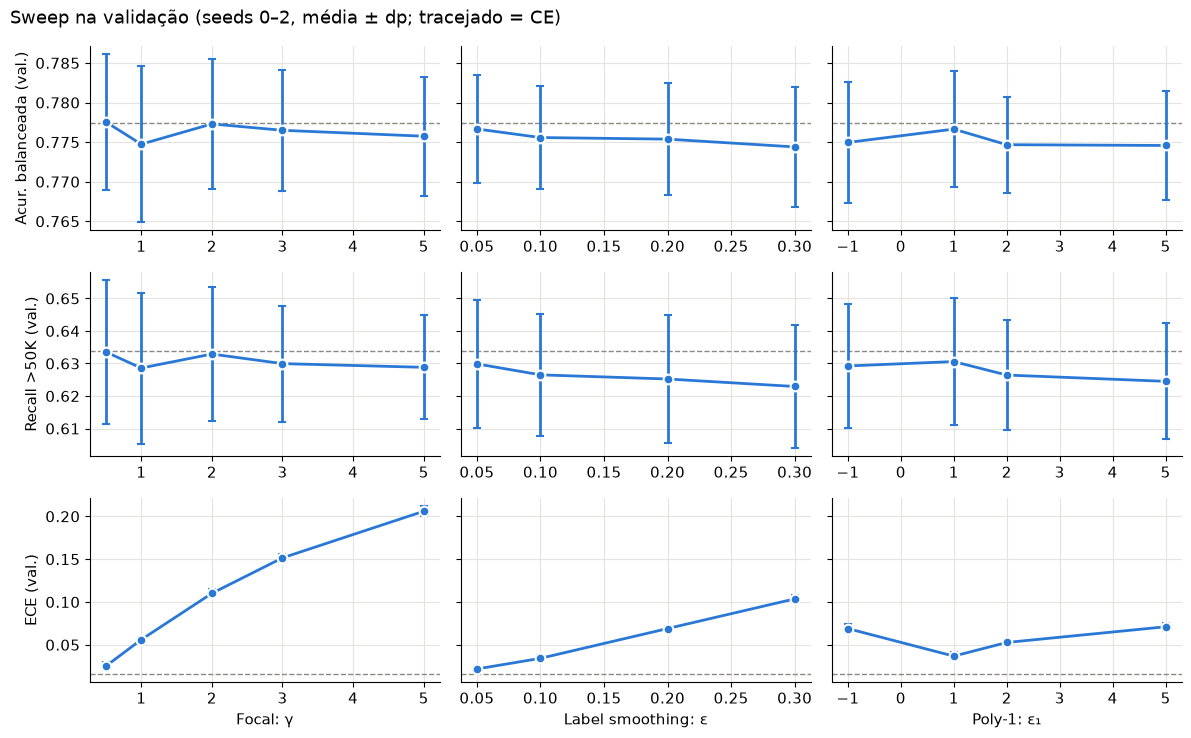

In [13]:
families = [("focal", "Focal: γ"), ("ls", "Label smoothing: ε"), ("poly1", "Poly-1: ε₁")]
metrics_to_plot = [("balanced_accuracy", "Acur. balanceada (val.)"),
                   ("minority_recall", "Recall >50K (val.)"), ("ece", "ECE (val.)")]
ce_rows = [row for row in sweep if row["family"] == "ce"]

fig, axes = plt.subplots(3, 3, figsize=(12, 7.5), sharey="row")
for col, (family, x_label) in enumerate(families):
    params = sorted({row["param"] for row in sweep if row["family"] == family})
    for line, (metric, y_label) in enumerate(metrics_to_plot):
        ax = axes[line, col]
        stats = [mean_and_std([row["val"][metric] for row in sweep
                               if row["family"] == family and row["param"] == param])
                 for param in params]
        ax.axhline(np.mean([row["val"][metric] for row in ce_rows]), color=GRAY, ls="--", lw=1)
        ax.errorbar(params, [mean for mean, _ in stats], yerr=[std for _, std in stats],
                    color=BLUE, marker="o", ms=7, capsize=3, markeredgecolor="white",
                    markeredgewidth=1.5)
        if line == 2:
            ax.set_xlabel(x_label)
        if col == 0:
            ax.set_ylabel(y_label)
fig.suptitle("Sweep na validação (seeds 0–2, média ± dp; tracejado = CE)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig3_sweep_validation.png")
plt.show()

**O que o sweep mostra.** Nenhum $\gamma$, $\varepsilon$ ou $\varepsilon_1$ passa da CE na
acurácia balanceada. As diferenças entre valores (milésimos) são menores que o desvio entre
seeds (≈ 0,008), então a "escolha" do melhor valor é em boa parte ruído: o que sai daqui é
o valor menos agressivo de cada família. O ECE, ao contrário, piora com clareza conforme o
hiperparâmetro cresce.



## 7. Etapa 2: runs finais no teste

Dez seeds (0–9) por configuração, medidas no `adult.test`:

- CE e CE ponderada;
- focal, label smoothing e Poly-1 com o valor escolhido na etapa 1;
- label smoothing com $\varepsilon \in \{0{,}1;\ 0{,}2;\ 0{,}3\}$ e focal com $\gamma = 2$, de acordo com os autores.

In [14]:
FINAL_SEEDS = tuple(range(10))
EXTRA_FINAL = [("ls", 0.1), ("ls", 0.2), ("ls", 0.3), ("focal", 2.0)]

configs = [("ce", None),
           ("wce", None),
           ("focal", selected["focal"]),
           ("ls", selected["ls"]),
           ("poly1", selected["poly1"])]

configs += [config for config in EXTRA_FINAL if config not in configs]

if USE_CACHE and (RESULTS / "final.json").exists():
    runs = json.loads((RESULTS / "final.json").read_text())["runs"]
    print(f"finais lidos de results/ ({len(runs)} runs)")
else:
    runs, start = [], time.time()
    for number, (family, param) in enumerate(configs, start=1):
        for seed in FINAL_SEEDS:
            runs.append(run_one(family, param, seed, final=True))
        print(f"[{number:2d}/{len(configs)}] {label(family, param):24s} {time.time() - start:5.0f} s")
    (RESULTS / "final.json").write_text(json.dumps({"selected": selected, "runs": runs}, indent=1))

[ 1/9] CE                          49 s
[ 2/9] Weighted CE                 99 s
[ 3/9] Focal γ=0.5                149 s
[ 4/9] Label smoothing ε=0.05     197 s
[ 5/9] Poly-1 ε₁=1                246 s
[ 6/9] Label smoothing ε=0.1      294 s
[ 7/9] Label smoothing ε=0.2      342 s
[ 8/9] Label smoothing ε=0.3      391 s
[ 9/9] Focal γ=2                  440 s


### O custo: FLOPs de treino por loss

O contador do engine soma tudo o que foi executado durante os 100 passos. Se a comparação é
mesmo a FLOPs iguais, as diferenças entre losses têm de ser desprezíveis.

In [15]:
MAIN = ["CE", "Weighted CE", label("focal", selected["focal"]),
        label("ls", selected["ls"]), label("poly1", selected["poly1"])]
EXTRA = [name for name in dict.fromkeys(row["name"] for row in runs) if name not in MAIN]
THRESHOLD_ARM = "CE + limiar da validação"


def metric_values(name, metric, block="test"):
    """Os 10 valores de uma métrica, ordenados por seed (para o pareamento)."""
    if name == THRESHOLD_ARM:
        rows, block = [row for row in runs if row["name"] == "CE"], "test_at_val_threshold"
    else:
        rows = [row for row in runs if row["name"] == name]
    return np.array([row[block][metric] for row in sorted(rows, key=lambda row: row["seed"])])


def train_flops_of(name):
    return [row for row in runs if row["name"] == name][0]["train_flops"]


ce_flops = train_flops_of("CE")
lines = ["| Loss | FLOPs de treino | vs CE |", "|---|---|---|"]
for name in MAIN + EXTRA:
    flops = train_flops_of(name)
    lines.append(f"| {name} | {flops:,} | {100 * (flops / ce_flops - 1):+.3f} % |")
lines.append(f"| {THRESHOLD_ARM} | {ce_flops:,} | +0.000 % (a busca do limiar é NumPy, fora do grafo) |")
display(Markdown("\n".join(lines)))

| Loss | FLOPs de treino | vs CE |
|---|---|---|
| CE | 84,222,572,300 | +0.000 % |
| Weighted CE | 84,225,177,400 | +0.003 % |
| Focal γ=0.5 | 84,232,991,900 | +0.012 % |
| Label smoothing ε=0.05 | 84,225,177,200 | +0.003 % |
| Poly-1 ε₁=1 | 84,235,596,700 | +0.015 % |
| Label smoothing ε=0.1 | 84,225,177,200 | +0.003 % |
| Label smoothing ε=0.2 | 84,225,177,200 | +0.003 % |
| Label smoothing ε=0.3 | 84,225,177,200 | +0.003 % |
| Focal γ=2 | 84,232,991,900 | +0.012 % |
| CE + limiar da validação | 84,222,572,300 | +0.000 % (a busca do limiar é NumPy, fora do grafo) |

## 8. O que cada loss compra na classe minoritária

Primeiro a tabela completa, depois as diferenças **pareadas** contra a CE. Como a seed $s$ dá a
todas as losses a mesma divisão e a mesma inicialização, comparamos $\Delta_s =
\text{métrica}_s(\text{loss}) - \text{métrica}_s(\text{CE})$ e testamos
$t = \bar\Delta / (s_\Delta / \sqrt{10})$; $|t| > 2{,}26$ é $p < 0{,}05$ com 9 graus de
liberdade (sem correção para comparações múltiplas).

In [16]:
def mean_std_text(values, decimals=3):
    mean, std = mean_and_std(values)
    return f"{mean:.{decimals}f} ± {std:.{decimals}f}"


TEST_COLUMNS = [("accuracy", "Acurácia"), ("minority_precision", "Precisão >50K"),
                ("minority_recall", "Recall >50K"), ("balanced_accuracy", "Acur. balanceada"),
                ("roc_auc", "ROC-AUC"), ("ece", "ECE")]
arms = MAIN + [THRESHOLD_ARM] + EXTRA
lines = ["| Loss | " + " | ".join(title for _, title in TEST_COLUMNS) + " |",
         "|---|" + "---|" * len(TEST_COLUMNS)]
for name in arms:
    lines.append(f"| {name} | " + " | ".join(mean_std_text(metric_values(name, metric))
                                             for metric, _ in TEST_COLUMNS) + " |")
display(Markdown("**Teste, limiar 0,5, 10 seeds (média ± dp)**\n\n" + "\n".join(lines)))

PAIRED_COLUMNS = TEST_COLUMNS[1:]                     # tudo menos a acurácia simples
lines = ["| Loss | " + " | ".join(title for _, title in PAIRED_COLUMNS) + " |",
         "|---|" + "---|" * len(PAIRED_COLUMNS)]
for name in arms[1:]:
    cells = []
    for metric, _ in PAIRED_COLUMNS:
        delta = metric_values(name, metric) - metric_values("CE", metric)
        mean, std = mean_and_std(delta)
        if std == 0:
            cells.append("idêntico")
            continue
        t_stat = mean / (std / np.sqrt(len(delta)))
        cells.append(f"{mean:+.4f} (t={t_stat:+.1f}){' *' if abs(t_stat) > 2.26 else ''}")
    lines.append(f"| {name} | " + " | ".join(cells) + " |")
display(Markdown("**Δ pareado contra a CE** (`*` = |t| > 2,26)\n\n" + "\n".join(lines)))

**Teste, limiar 0,5, 10 seeds (média ± dp)**

| Loss | Acurácia | Precisão >50K | Recall >50K | Acur. balanceada | ROC-AUC | ECE |
|---|---|---|---|---|---|---|
| CE | 0.855 ± 0.001 | 0.724 ± 0.005 | 0.626 ± 0.004 | 0.776 ± 0.002 | 0.908 ± 0.001 | 0.013 ± 0.002 |
| Weighted CE | 0.814 ± 0.002 | 0.572 ± 0.004 | 0.836 ± 0.007 | 0.821 ± 0.002 | 0.905 ± 0.001 | 0.042 ± 0.003 |
| Focal γ=0.5 | 0.855 ± 0.001 | 0.724 ± 0.004 | 0.626 ± 0.005 | 0.776 ± 0.002 | 0.908 ± 0.001 | 0.025 ± 0.002 |
| Label smoothing ε=0.05 | 0.857 ± 0.001 | 0.731 ± 0.006 | 0.623 ± 0.005 | 0.776 ± 0.002 | 0.908 ± 0.001 | 0.018 ± 0.001 |
| Poly-1 ε₁=1 | 0.856 ± 0.001 | 0.729 ± 0.004 | 0.624 ± 0.005 | 0.776 ± 0.002 | 0.909 ± 0.001 | 0.036 ± 0.001 |
| CE + limiar da validação | 0.803 ± 0.013 | 0.555 ± 0.023 | 0.858 ± 0.025 | 0.822 ± 0.001 | 0.908 ± 0.001 | 0.013 ± 0.002 |
| Label smoothing ε=0.1 | 0.857 ± 0.001 | 0.732 ± 0.005 | 0.623 ± 0.006 | 0.776 ± 0.002 | 0.907 ± 0.001 | 0.033 ± 0.002 |
| Label smoothing ε=0.2 | 0.857 ± 0.001 | 0.734 ± 0.006 | 0.619 ± 0.007 | 0.775 ± 0.003 | 0.906 ± 0.001 | 0.069 ± 0.002 |
| Label smoothing ε=0.3 | 0.857 ± 0.001 | 0.735 ± 0.005 | 0.619 ± 0.006 | 0.775 ± 0.002 | 0.906 ± 0.001 | 0.107 ± 0.002 |
| Focal γ=2 | 0.855 ± 0.002 | 0.724 ± 0.005 | 0.625 ± 0.006 | 0.776 ± 0.003 | 0.908 ± 0.001 | 0.111 ± 0.005 |

**Δ pareado contra a CE** (`*` = |t| > 2,26)

| Loss | Precisão >50K | Recall >50K | Acur. balanceada | ROC-AUC | ECE |
|---|---|---|---|---|---|
| Weighted CE | -0.1523 (t=-76.2) * | +0.2094 (t=+76.8) * | +0.0449 (t=+52.3) * | -0.0031 (t=-7.7) * | +0.0297 (t=+24.9) * |
| Focal γ=0.5 | -0.0005 (t=-0.6) | -0.0001 (t=-0.1) | -0.0001 (t=-0.4) | -0.0003 (t=-2.0) | +0.0124 (t=+10.9) * |
| Label smoothing ε=0.05 | +0.0061 (t=+8.7) * | -0.0036 (t=-2.9) * | -0.0005 (t=-0.9) | -0.0005 (t=-2.8) * | +0.0050 (t=+6.9) * |
| Poly-1 ε₁=1 | +0.0044 (t=+10.9) * | -0.0024 (t=-3.3) * | -0.0003 (t=-0.8) | +0.0002 (t=+1.9) | +0.0234 (t=+60.3) * |
| CE + limiar da validação | -0.1694 (t=-23.4) * | +0.2320 (t=+27.8) * | +0.0458 (t=+58.9) * | idêntico | idêntico |
| Label smoothing ε=0.1 | +0.0074 (t=+8.1) * | -0.0038 (t=-2.2) | -0.0003 (t=-0.4) | -0.0013 (t=-6.4) * | +0.0208 (t=+20.8) * |
| Label smoothing ε=0.2 | +0.0099 (t=+7.5) * | -0.0069 (t=-3.2) * | -0.0013 (t=-1.3) | -0.0021 (t=-13.6) * | +0.0568 (t=+49.1) * |
| Label smoothing ε=0.3 | +0.0111 (t=+8.8) * | -0.0072 (t=-4.3) * | -0.0012 (t=-1.6) | -0.0027 (t=-14.3) * | +0.0941 (t=+89.9) * |
| Focal γ=2 | -0.0008 (t=-0.6) | -0.0009 (t=-0.6) | -0.0006 (t=-0.7) | -0.0008 (t=-2.3) * | +0.0987 (t=+49.9) * |

### A tabela e a figura do protocolo: `summarize()` e `pareto()`

O relatório do projeto pede a tabela de `summarize()` com o baseline nela e a figura de
`pareto()`, para que esta questão possa ser lida ao lado das outras catorze. Os runs viram
objetos `Result` do `benchmark.py`. Como a pergunta é sobre a classe minoritária, o `score`
é a **acurácia balanceada**; a segunda tabela repete com a acurácia simples. `summarize`
marca se cada diferença para o baseline fica dentro de um desvio-padrão.

In [17]:
def as_results(metric):
    """Converte os runs em objetos Result do benchmark, com score = a métrica pedida."""
    results = []
    for name in MAIN + [THRESHOLD_ARM] + EXTRA:
        source_name = "CE" if name == THRESHOLD_ARM else name
        rows = sorted([row for row in runs if row["name"] == source_name], key=lambda row: row["seed"])
        for row, score in zip(rows, metric_values(name, metric)):
            results.append(Result(name=name, seed=row["seed"], score=float(score),
                                  train_flops=row["train_flops"], infer_flops=row["infer_flops"],
                                  seconds=row["seconds"], extra={"n_params": row["n_params"]}))
    return results


balanced_results = as_results("balanced_accuracy")
print("score = acurácia balanceada no teste\n")
print(summarize(balanced_results, baseline="CE"))
print("\n\nscore = acurácia no teste\n")
print(summarize(as_results("accuracy"), baseline="CE"))

score = acurácia balanceada no teste

configuration                 n             score   train GFLOP   infer MFLOP     params    s/run
-------------------------------------------------------------------------------------------------
CE                           10    0.7763 ± 0.0016         84.22         232.4      7,106      4.8
Weighted CE                  10    0.8212 ± 0.0022         84.23         232.4      7,106      4.9
Focal γ=0.5                  10    0.7762 ± 0.0019         84.23         232.4      7,106      4.9
Label smoothing ε=0.05       10    0.7758 ± 0.0017         84.23         232.4      7,106      4.7
Poly-1 ε₁=1                  10    0.7760 ± 0.0017         84.24         232.4      7,106      4.8
CE + limiar da validação     10    0.8221 ± 0.0015         84.22         232.4      7,106      4.8
Label smoothing ε=0.1        10    0.7760 ± 0.0022         84.23         232.4      7,106      4.6
Label smoothing ε=0.2        10    0.7750 ± 0.0027         84.23         

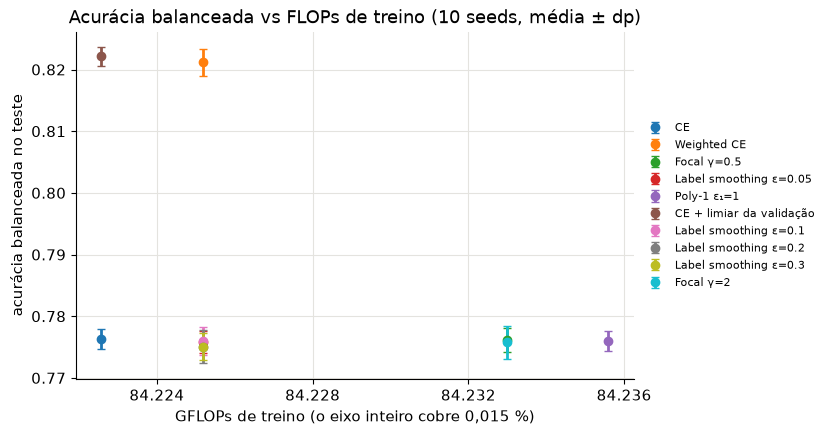

In [18]:
from matplotlib.ticker import FuncFormatter, MaxNLocator

ax = pareto(balanced_results, cost="train_flops", annotate=False,
            title="Acurácia balanceada vs FLOPs de treino (10 seeds, média ± dp)")
ax.set_xscale("linear")
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.xaxis.set_major_formatter(FuncFormatter(lambda flops, _: f"{flops / 1e9:.3f}"))
ax.set_xlabel("GFLOPs de treino (o eixo inteiro cobre 0,015 %)")
ax.set_ylabel("acurácia balanceada no teste")
ax.legend(fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.figure.savefig(FIGURES / "fig0_pareto_flops.png")
plt.show()

O eixo horizontal está ampliado ao extremo: ele inteiro cobre só 0,015 % do custo de
treino, a diferença entre a loss mais barata e a mais cara. Na prática todos os braços custam
o mesmo, então a comparação é de fato a FLOPs iguais e o eixo que importa é o vertical. Nele,
só a CE ponderada e o limiar ajustado saem da faixa da CE.

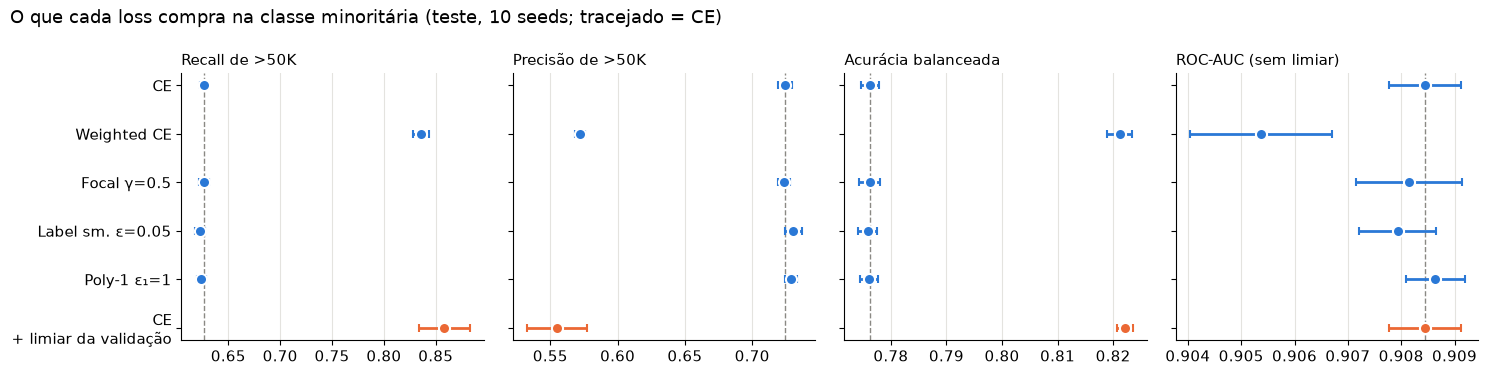

In [19]:
arms = MAIN + [THRESHOLD_ARM]
panels = [("minority_recall", "Recall de >50K"), ("minority_precision", "Precisão de >50K"),
          ("balanced_accuracy", "Acurácia balanceada"), ("roc_auc", "ROC-AUC (sem limiar)")]


def short_name(name):
    return name.replace("Label smoothing", "Label sm.").replace(" + limiar", "\n+ limiar")


fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
y_positions = np.arange(len(arms))[::-1]
for ax, (metric, title) in zip(axes, panels):
    ax.axvline(metric_values("CE", metric).mean(), color=GRAY, lw=1, ls="--")
    for y_position, name in zip(y_positions, arms):
        mean, std = mean_and_std(metric_values(name, metric))
        color = ORANGE if name == THRESHOLD_ARM else BLUE
        ax.errorbar(mean, y_position, xerr=std, fmt="o", ms=8, color=color, capsize=3,
                    markeredgecolor="white", markeredgewidth=1.5)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y_positions, [short_name(name) for name in arms])
fig.suptitle("O que cada loss compra na classe minoritária (teste, 10 seeds; tracejado = CE)",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig1_minority_metrics.png")
plt.show()

Se a CE ponderada só desloca o limiar, os pontos de operação de todas as losses têm de cair
sobre a **mesma curva precisão-recall**. A figura abaixo desenha a curva PR da própria CE
(seed 0, teste) e coloca em cima o ponto de cada seed de cada braço.

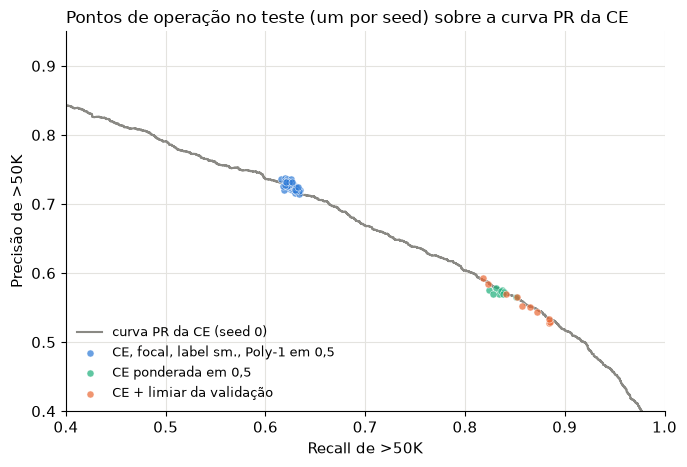

In [20]:
# Curva precisão-recall da CE (seed 0): ordena as pessoas pela p(>50K) e, a cada posição,
# mede precisão e recall de quem ficou acima dela.
ce_test_probs = np.load(RESULTS / "proj_ce_None.npz")["test_probs"]
labels_by_prob = test_ds.y[np.argsort(-ce_test_probs, kind="mergesort")]
found_so_far = np.cumsum(labels_by_prob)
recall_curve = found_so_far / labels_by_prob.sum()
precision_curve = found_so_far / np.arange(1, len(labels_by_prob) + 1)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(recall_curve, precision_curve, color=GRAY, lw=1.5, label="curva PR da CE (seed 0)")
groups = [("CE, focal, label sm., Poly-1 em 0,5", MAIN[:1] + MAIN[2:], BLUE),
          ("CE ponderada em 0,5", ["Weighted CE"], AQUA),
          ("CE + limiar da validação", [THRESHOLD_ARM], ORANGE)]
for group_label, names, color in groups:
    recalls = np.concatenate([metric_values(name, "minority_recall") for name in names])
    precisions = np.concatenate([metric_values(name, "minority_precision") for name in names])
    ax.scatter(recalls, precisions, s=26, color=color, alpha=0.7, edgecolor="white",
               linewidth=0.5, label=group_label, zorder=3)
ax.set_xlim(0.4, 1.0); ax.set_ylim(0.4, 0.95)
ax.set_xlabel("Recall de >50K"); ax.set_ylabel("Precisão de >50K")
ax.set_title("Pontos de operação no teste (um por seed) sobre a curva PR da CE", loc="left", fontsize=12)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "fig2_operating_points.png")
plt.show()

**Leitura.** Na execução de referência:

1. **Focal, label smoothing e Poly-1 não compram nada na classe minoritária.** A acurácia
   balanceada fica dentro do ruído da CE (|Δ| ≤ 0,0013, |t| ≤ 1,6). Label smoothing e Poly-1
   trocam um pouco de recall por precisão (Δ recall de −0,004 e −0,002, t ≈ −3), na direção errada para a
   pergunta.
2. **Só a CE ponderada move o `>50K`**: recall de 0,626 para 0,836 e acurácia balanceada de
   0,776 para 0,821. Mas o ponto dela está **sobre a curva PR da CE**: ela não aprendeu a
   ordenar melhor (o ROC-AUC até cai, 0,9084 → 0,9054, t = −7,7), só escolheu outro ponto da
   curva.
3. **O controle de custo zero chega ao mesmo lugar.** A CE com o limiar escolhido na
   validação dá acurácia balanceada 0,822, sem nenhum FLOP a mais e sem mexer na calibração.

## 9. Calibração

Os diagramas abaixo juntam as 15 faixas das 10 seeds. Abaixo da diagonal o modelo promete
mais do que acerta (superconfiante); acima, promete menos (subconfiante).

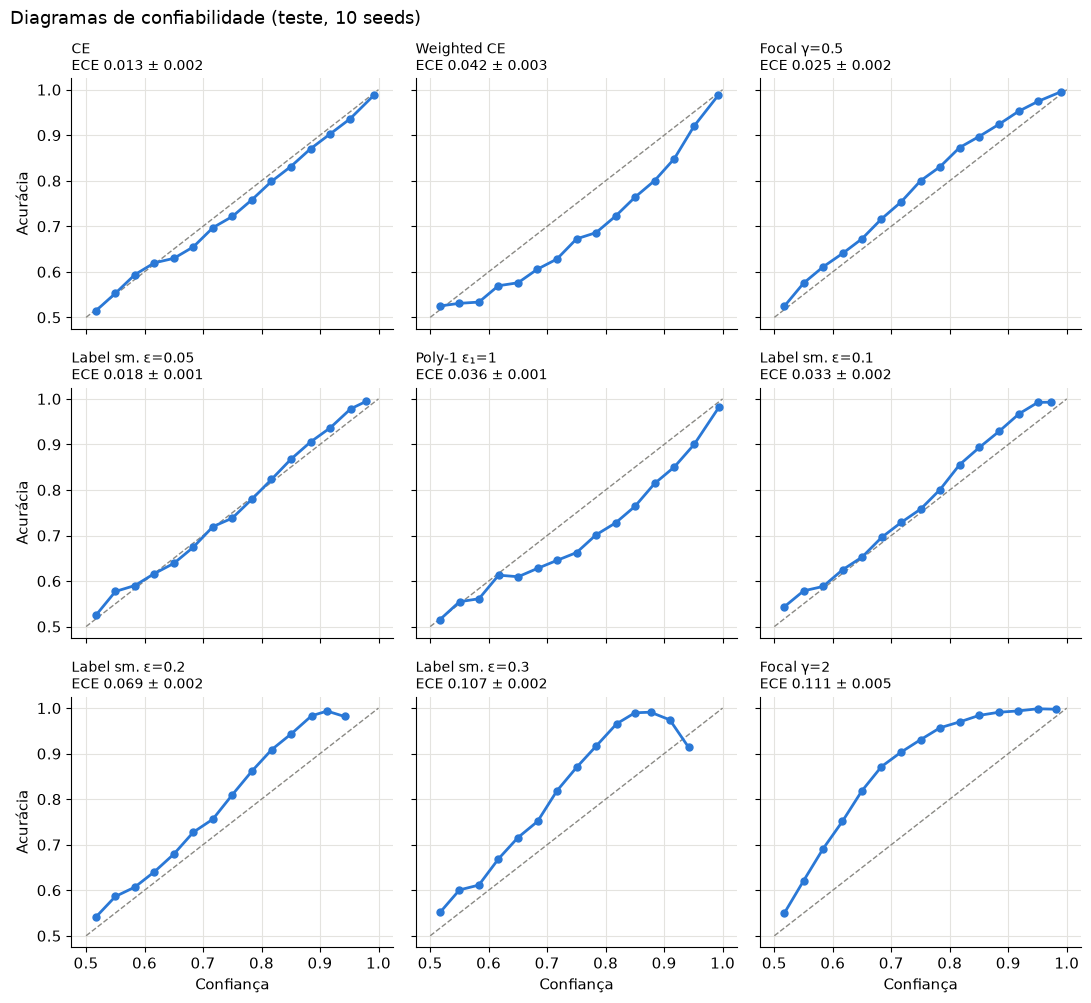

In [21]:
arms = MAIN + [name for name in EXTRA if name.startswith(("Label", "Focal"))]
n_rows = int(np.ceil(len(arms) / 3))
fig, axes = plt.subplots(n_rows, 3, figsize=(11, 3.4 * n_rows), sharex=True, sharey=True)
for ax, name in zip(axes.flat, arms):
    rows = [row for row in runs if row["name"] == name]
    count = np.array([row["reliability"]["count"] for row in rows], dtype=float)
    confidence = np.nan_to_num(np.array([row["reliability"]["confidence"] for row in rows], dtype=float))
    accuracy = np.nan_to_num(np.array([row["reliability"]["accuracy"] for row in rows], dtype=float))
    total = count.sum(axis=0)
    enough = total > 50                                    # esconde faixas quase vazias
    pooled_confidence = (confidence * count).sum(axis=0)[enough] / total[enough]
    pooled_accuracy = (accuracy * count).sum(axis=0)[enough] / total[enough]
    ax.plot([0.5, 1], [0.5, 1], color=GRAY, lw=1, ls="--")
    ax.plot(pooled_confidence, pooled_accuracy, color=BLUE, marker="o", ms=5)
    ax.set_title(f"{short_name(name)}\nECE {mean_std_text(metric_values(name, 'ece'))}",
                 loc="left", fontsize=10)
for ax in axes.flat[len(arms):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("Confiança")
for ax in axes[:, 0]:
    ax.set_ylabel("Acurácia")
fig.suptitle("Diagramas de confiabilidade (teste, 10 seeds)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig4_reliability.png")
plt.show()

**Leitura.** A CE já sai bem calibrada neste problema (ECE ≈ 0,013). Focal e label smoothing
deixam o modelo **subconfiante**, cada vez mais conforme $\gamma$ ou $\varepsilon$ crescem
(ECE ≈ 0,11 com $\gamma = 2$ ou $\varepsilon = 0{,}3$). CE ponderada e Poly-1 ficam
**superconfiantes** para a classe que favorecem.

Isso é o contrário do que Müller et al. relatam, mas por um motivo conhecido: eles partem de
redes profundas superconfiantes, onde suavizar ajuda. Um MLP raso treinado 100 passos não
tem esse excesso para corrigir.

## 10. A geometria da penúltima camada

Agora a segunda metade da pergunta. Primeiro a figura no estilo da Fig. 1 de Müller et al.
(seed 0), em unidades da distância entre os centros das classes, para que losses com escalas
diferentes fiquem comparáveis.

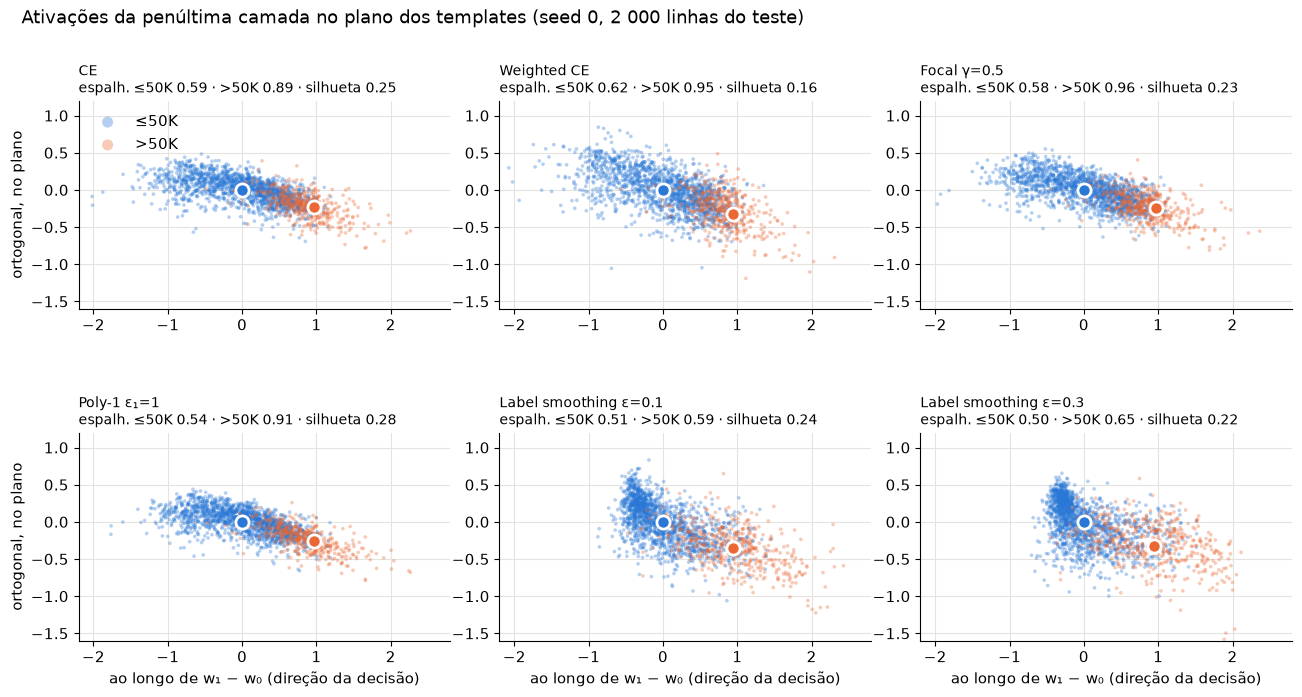

In [22]:
shown = [("ce", None), ("wce", None), ("focal", selected["focal"]), ("poly1", selected["poly1"]),
         ("ls", 0.1), ("ls", 0.3)]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, (family, param) in zip(axes.flat, shown):
    saved = np.load(RESULTS / f"proj_{family}_{param}.npz")
    plane, labels = saved["plane"], saved["labels"]
    # unidades da distância entre os centros, com o centro <=50K na origem
    center_majority, center_minority = plane[labels == 0].mean(0), plane[labels == 1].mean(0)
    scaled = (plane - center_majority) / np.linalg.norm(center_minority - center_majority)
    for c, color, class_name in ((0, BLUE, "≤50K"), (1, ORANGE, ">50K")):
        ax.scatter(scaled[labels == c, 0], scaled[labels == c, 1], s=7, color=color, alpha=0.35,
                   edgecolor="none", label=class_name, rasterized=True)
        ax.scatter(*scaled[labels == c].mean(0), s=90, color=color, edgecolor="white",
                   linewidth=2, zorder=5)
    seed0 = [row for row in runs if row["family"] == family and row["param"] == param
             and row["seed"] == 0][0]["geometry"]
    ax.set_title(f"{label(family, param)}\nespalh. ≤50K {seed0['spread_majority']:.2f} · "
                 f">50K {seed0['spread_minority']:.2f} · silhueta {seed0['silhouette']:.2f}",
                 loc="left", fontsize=10)
    ax.set_xlim(-2.2, 2.8); ax.set_ylim(-1.6, 1.2); ax.set_aspect("equal")
axes[0, 0].legend(loc="upper left", frameon=False, markerscale=3)
for ax in axes[-1]:
    ax.set_xlabel("ao longo de w₁ − w₀ (direção da decisão)")
for ax in axes[:, 0]:
    ax.set_ylabel("ortogonal, no plano")
fig.suptitle("Ativações da penúltima camada no plano dos templates (seed 0, 2 000 linhas do teste)",
             x=0.01, ha="left")
fig.tight_layout(h_pad=2.5)
fig.savefig(FIGURES / "fig5_template_projection.png")
plt.show()

In [23]:
GEOMETRY_COLUMNS = [("silhouette", "silhouette_score (cosseno, 64-d)"),
                    ("spread_majority", "Espalh. ≤50K"), ("spread_minority", "Espalh. >50K")]
lines = ["| Loss | " + " | ".join(title for _, title in GEOMETRY_COLUMNS) + " |",
         "|---|" + "---|" * len(GEOMETRY_COLUMNS)]
for name in MAIN + EXTRA:
    lines.append(f"| {name} | " + " | ".join(mean_std_text(metric_values(name, metric, "geometry"))
                                             for metric, _ in GEOMETRY_COLUMNS) + " |")
display(Markdown("**Geometria, 10 seeds (média ± dp)**\n\n" + "\n".join(lines)))

**Geometria, 10 seeds (média ± dp)**

| Loss | silhouette_score (cosseno, 64-d) | Espalh. ≤50K | Espalh. >50K |
|---|---|---|---|
| CE | 0.257 ± 0.021 | 0.615 ± 0.027 | 0.900 ± 0.077 |
| Weighted CE | 0.167 ± 0.025 | 0.651 ± 0.038 | 0.906 ± 0.078 |
| Focal γ=0.5 | 0.239 ± 0.025 | 0.615 ± 0.030 | 0.943 ± 0.063 |
| Label smoothing ε=0.05 | 0.259 ± 0.020 | 0.509 ± 0.035 | 0.759 ± 0.093 |
| Poly-1 ε₁=1 | 0.280 ± 0.017 | 0.568 ± 0.022 | 0.930 ± 0.084 |
| Label smoothing ε=0.1 | 0.250 ± 0.023 | 0.512 ± 0.040 | 0.646 ± 0.039 |
| Label smoothing ε=0.2 | 0.239 ± 0.022 | 0.494 ± 0.037 | 0.657 ± 0.047 |
| Label smoothing ε=0.3 | 0.228 ± 0.024 | 0.495 ± 0.035 | 0.681 ± 0.052 |
| Focal γ=2 | 0.206 ± 0.027 | 0.638 ± 0.031 | 0.967 ± 0.074 |

### Dose-resposta do label smoothing

Se o smoothing aperta os clusters, o efeito deve crescer com $\varepsilon$. E se apertar os
clusters fosse o que ajuda o classificador, AUC e recall deveriam crescer junto. A figura põe
as duas coisas lado a lado: geometria em azul, desempenho em laranja.

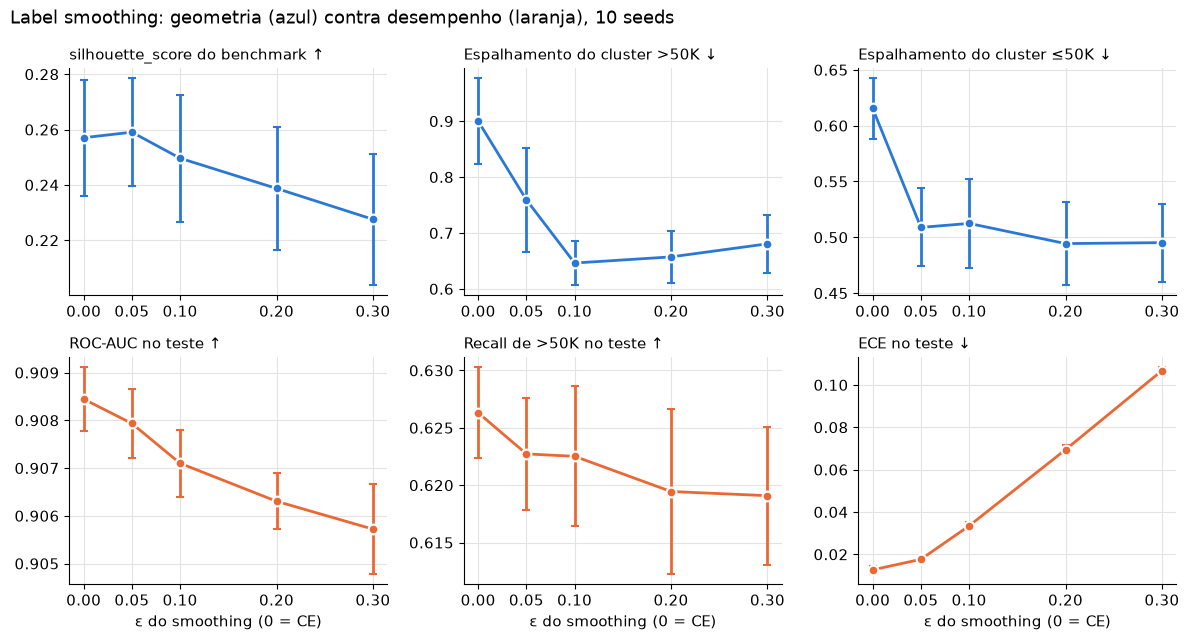

In [24]:
epsilons = [0.0] + sorted({row["param"] for row in runs if row["family"] == "ls"})


def name_for(epsilon):
    return "CE" if epsilon == 0 else label("ls", epsilon)


panels = [("geometry", "silhouette", "silhouette_score do benchmark ↑"),
          ("geometry", "spread_minority", "Espalhamento do cluster >50K ↓"),
          ("geometry", "spread_majority", "Espalhamento do cluster ≤50K ↓"),
          ("test", "roc_auc", "ROC-AUC no teste ↑"),
          ("test", "minority_recall", "Recall de >50K no teste ↑"),
          ("test", "ece", "ECE no teste ↓")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, (block, metric, title) in zip(axes.flat, panels):
    stats = [mean_and_std(metric_values(name_for(epsilon), metric, block)) for epsilon in epsilons]
    ax.errorbar(epsilons, [mean for mean, _ in stats], yerr=[std for _, std in stats],
                color=BLUE if block == "geometry" else ORANGE, marker="o", ms=7, capsize=3,
                markeredgecolor="white", markeredgewidth=1.5)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xticks(epsilons)
for ax in axes[-1]:
    ax.set_xlabel("ε do smoothing (0 = CE)")
fig.suptitle("Label smoothing: geometria (azul) contra desempenho (laranja), 10 seeds", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig6_ls_dose_response.png")
plt.show()

**Leitura.** Na execução de referência:

- **No plano dos templates, o label smoothing aperta os clusters, como Müller et al. dizem, e
  de forma dose-dependente.** Com $\varepsilon = 0{,}1$ o espalhamento do `>50K` cai de 0,90
  para 0,65 e o do `≤50K` de 0,62 para 0,51. O efeito satura a partir de
  $\varepsilon \approx 0{,}1$.
- **A silhueta que a questão pede conta outra história.** O `silhouette_score` do
  `benchmark.py` usa distância **cosseno** nas 64 dimensões, e ela *cai* com o smoothing:
  0,257 na CE, 0,250 com $\varepsilon = 0{,}1$ (Δ pareado −0,007, t = −2,2) e 0,228 com
  $\varepsilon = 0{,}3$ (Δ −0,029, t = −6,3). Como o espalhamento é euclidiano e a silhueta é
  angular, o "aperto" é de **tamanho**: o smoothing encolhe as ativações dos exemplos fáceis,
  mas não deixa as direções das duas classes mais separadas. Todas as losses ficam bem acima
  do ponto zero das features de entrada (0,074).
- **Focal faz o oposto** (espalhamento do `>50K` 0,97 e silhueta 0,206 com $\gamma = 2$).
  **Poly-1** é a única loss que sobe a silhueta (0,280, t = +10,3), sem que isso apareça em
  nenhuma métrica de classificação.
- **O aperto não vira desempenho.** Enquanto o espalhamento "melhora", o ROC-AUC cai
  monotonicamente (0,9084 → 0,9057 em $\varepsilon = 0{,}3$), o recall de `>50K` cai e o ECE
  sobe.

Por que clusters mais apertados não dão um AUC maior? Com duas classes, a decisão depende só
da projeção em $w_1 - w_0$, e o AUC mede exatamente quanto as classes se sobrepõem nesse eixo.
O espalhamento cai porque o smoothing **limita os logits**: a cauda de exemplos muito fáceis,
que a CE empurra para longe, é puxada de volta e o raio dos clusters encolhe. A ordem dos
exemplos perto da fronteira, que é o que importa para a classe minoritária, fica igual ou
piora. É o outro argumento do próprio Müller et al.: o smoothing apaga informação sobre
*quão* típico é cada exemplo.

## 11. Resposta e ressalvas

**Qual loss compra mais na classe minoritária a FLOPs iguais?** A CE ponderada, e só ela, mas
o que ela compra é um deslocamento do limiar de decisão. Ajustar o limiar da CE na validação
faz o mesmo de graça e mantém a calibração. Focal, label smoothing e Poly-1 não compram nada
mensurável. Todas custam o mesmo: 84,22 GFLOP de treino, com diferença máxima de +0,015 %.

**Muda a geometria como Müller et al. afirmam?** Em parte, e depende da régua. No plano dos
templates, o espalhamento de cada classe cai com o label smoothing de forma dose-dependente,
como no artigo. Com o `silhouette_score` do benchmark (cosseno, 64-d), que é a medida pedida
pela questão, a silhueta *cai*: o aperto é de tamanho, não de direção. Nos dois
casos o aperto não melhora a separação que o classificador usa e vem com AUC menor e
calibração pior.

**Acurácia contra calibração.** A questão lembra que o smoothing costuma trocar acurácia por
calibração. Aqui a troca aparece ao contrário: o smoothing ganha um pouco de acurácia simples
(+0,0015 a +0,0020 com $\varepsilon \ge 0{,}1$, fora de 1 dp no `summarize`), ganho que vem da
classe majoritária, e perde calibração (ECE de 0,013 para até 0,107).

### Veredito das hipóteses

| Hipótese | Resultado | Evidência |
|---|---|---|
| H1: nenhuma loss de formato melhora a acurácia balanceada além de 1 dp | **confirmada** | `summarize`: todos "within noise"; Δ pareado ≤ 0,0013, \|t\| ≤ 1,6 |
| H2: a CE ponderada equivale a deslocar o limiar | **confirmada** | CE + limiar 0,822 ± 0,002 contra CE ponderada 0,821 ± 0,002; mesma curva PR |
| H3: o smoothing sobe a silhueta e aperta os clusters | **parcial** | espalhamento no plano dos templates: cai, dose-dependente; `silhouette_score` cosseno: não sobe, cai (t = −6,3 em ε = 0,3) |
| H4: o aperto não melhora o ROC-AUC | **confirmada** | ROC-AUC cai de 0,9084 para 0,9057 com ε |

**Ressalvas para dizer na apresentação**

- O contador de FLOPs do engine é exato para os matmuls e aproximado para as operações
  elemento a elemento (uma por elemento, softmax como 3). As losses só diferem nessas
  operações, então a diferença real pode não ser exatamente +0,015 %, mas é de qualquer
  forma desprezível perto dos matmuls.

- Um dataset tabular, um MLP raso de 64 unidades, 100 passos full-batch. Em redes profundas
  superconfiantes (o cenário dos artigos) o resultado de calibração pode se inverter.
- Com $K = 2$, a parte "equidistante dos templates das outras classes" da afirmação de Müller
  não é testável.
- A seleção do sweep usou 3 seeds, cujo desvio (≈ 0,008) é maior que as diferenças entre
  configurações.
- Os testes t pareados não têm correção para comparações múltiplas.
- A focal foi usada sem o termo $\alpha$.

**Próximos passos baratos:** focal com $\alpha$; um alvo com 3 ou mais classes para testar a
equidistância; um modelo mais largo ou treinado por mais tempo, onde a CE fique
superconfiante.

## 12. Reprodução

- **Comando:** abra este notebook e rode as células de cima para baixo com `USE_CACHE = False`.
- **Seeds:** 0, 1 e 2 no sweep; 0 a 9 nos runs finais; amostra da geometria fixa pela seed
  12345 do `default_rng`.
- **Dependências:** só o repositório (`bert_cpu`, `datasets`, `research/benchmark.py`), NumPy
  e matplotlib para as figuras.
- **Saídas:** `results/sweep.json`, `results/final.json`, `results/proj_*.npz` e
  `figures/*.png`.

A célula abaixo mede o custo de relógio do estudo inteiro nesta execução.

In [25]:
n_trained = len(sweep) + len(runs)
print(f"{n_trained} treinos ({len(sweep)} no sweep, {len(runs)} finais) + 1 baseline")
print(f"tempo total do notebook: {(time.time() - START_TIME) / 60:.1f} min")
print(f"FLOPs de treino somados: {sum(row['train_flops'] for row in sweep + runs) / 1e12:.2f} TFLOP")

135 treinos (45 no sweep, 90 finais) + 1 baseline
tempo total do notebook: 11.0 min
FLOPs de treino somados: 11.37 TFLOP
